# Imporation des packages

In [1]:
# Import des librairies nécessaires
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.ensemble import IsolationForest

In [2]:
# Read the file into dataframes
import pandas as pd
data = pd.read_excel("DATA BI.xlsx",index_col=False,keep_default_na=True,sheet_name='DEPENSES', header=2)
print(data.head())


   N°  Unnamed: 1       DATE  NCG             ICG     NCT   NCG.1  \
0   1           1 2023-01-12  401         FSR AUX  401S02  228300   
1   2           1 2023-01-05  401         FSR AUX  401S02  615002   
2   3           1 2023-01-16  401         FSR AUX  401D02  606200   
3   4           1 2023-01-26  401         FSR AUX  401D01  606100   
4   5           1 2023-01-04  402  SOUS TRAITANTS  402S01  611002   

          N° FCT                                        DESCRIPTION  SODEXO  \
0        23-0013                                      IMPRIMANTE HP     NaN   
1        23-0008                             reparation imprimante      NaN   
2       00001317                             produits bureautiques      NaN   
3             05                                           spot led     NaN   
4  2023BLF/00003  PROJET:- realisation d4un prog de transformati...     NaN   

        HT      TVA   TF       TTC      RS    NET RS  \
0  4150.00  290.500  1.0  4441.500  44.415  4397.085  

In [3]:
# Desciption de la base de données
data.describe()


,N°,Unnamed: 1,DATE,NCG,NCG.1,SODEXO,HT,TVA,TF,TTC,RS,NET RS
count,588.000000,588.000000,588,588.000000,588.000000,14.000000,586.000000,451.000000,422.000000,587.000000,135.000000,417.000000
mean,295.333333,1.001701,2023-07-09 16:53:52.653061,21978.892857,607898.010204,2363.914857,404.661357,42.831963,1.469782,494.146212,87.133935,614.811510
min,1.000000,1.000000,2022-12-09 00:00:00,401.000000,228100.000000,0.000000,-4500.000000,-855.000000,0.000000,-5354.000000,0.000000,-5354.000000
25%,148.750000,1.000000,2023-04-01 00:00:00,401.000000,606500.000000,15.950000,20.000000,0.000000,0.000000,20.000000,0.000000,17.500000
50%,295.500000,1.000000,2023-07-14 00:00:00,401.000000,606500.000000,3420.550000,99.818500,0.000000,0.000000,100.000000,0.000000,70.000000
75%,442.250000,1.000000,2023-10-17 00:00:00,401.000000,623000.000000,3800.456000,196.924500,17.615140,1.000000,211.955000,160.000000,500.000000
max,589.000000,2.000000,2023-12-31 00:00:00,437910.000000,665402.000000,4007.800000,6302.000000,1197.380000,37.652000,7500.380000,750.038000,6750.342000
std,170.126262,0.041239,NaN,94816.541380,54226.932333,1829.929959,942.652007,152.604166,5.995234,1125.899138,136.283086,1249.926804


# Identification graphique des outliers

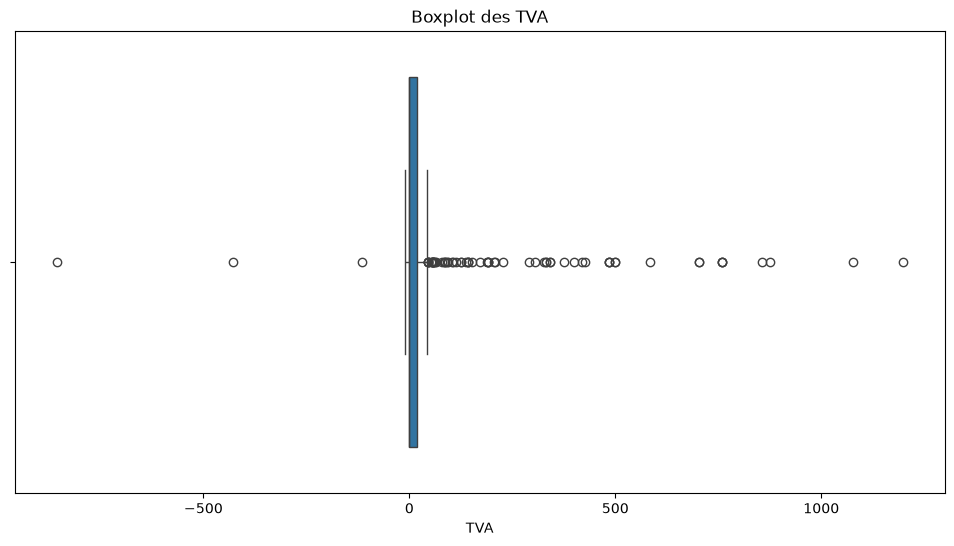

In [4]:
# Visualiser les outliers en utilisant un boxplot avec Seaborn
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='TVA')
plt.xlabel('TVA')
plt.title("Boxplot des TVA")
plt.show()

# Identification des outliers univariées

## Identification des outliers IQR

La méthode de l'IQR est une approche courante pour identifier les valeurs aberrantes dans des données univariées. Elle utilise l'écart interquartile pour définir une plage de valeurs plausibles et identifie les observations qui sont en dehors de cette plage.

### Définition

L'IQR est défini comme la différence entre le troisième quartile (Q3) et le premier quartile (Q1) de la distribution des données. Les bornes inférieure et supérieure de la plage plausible sont définies comme suit :

- Limite inférieure : Q1 - 1,5 x IQR
- Limite supérieure : Q3 + 1,5 x IQR

Les observations en dehors de ces bornes sont considérées comme des valeurs aberrantes.

### Avantages

La méthode de l'IQR est relativement simple à comprendre et à implémenter. Elle est également assez robuste aux valeurs aberrantes, car elle utilise la médiane et l'écart interquartile pour calculer les bornes plausibles.

### Inconvénients

La méthode de l'IQR peut ne pas fonctionner correctement dans certaines distributions non symétriques, car elle suppose une distribution normale ou presque normale des données. Elle peut également ne pas fonctionner correctement si les données contiennent de nombreux points de données aberrants.


In [5]:
# Identification des données aberrantes - IQR
# Fonction pour détecter les outliers en utilisant l'IQR
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return data[(data[column] < lower_bound) | (data[column] > upper_bound)]

# Trouver les outliers pour la colonne 'TVA'
outliers = detect_outliers_iqr(data, 'TVA')

# Afficher les outliers
print("Outliers détectés:")
print(outliers['TVA'])

Outliers détectés:
0      290.50000
3       45.49500
4      209.00000
5      760.00000
43      45.39974
         ...    
546     79.67232
548    484.50000
585    206.14400
586    188.81400
587     61.85300
Name: TVA, Length: 67, dtype: float64


## Identification des outliers avec Z-score

## Méthode du z-score

La méthode du z-score est une autre approche courante pour identifier les valeurs aberrantes dans des données univariées. Elle utilise l'écart à la moyenne pour définir une plage de valeurs plausibles et identifie les observations qui sont en dehors de cette plage.

### Définition

Le z-score est défini comme la différence entre une observation et la moyenne de la distribution des données, divisée par l'écart-type de la distribution :

z = (x - μ) / σ

Les bornes inférieure et supérieure de la plage plausible sont définies comme suit :

- Limite inférieure : μ - 3 x σ
- Limite supérieure : μ + 3 x σ

Les observations en dehors de ces bornes sont considérées comme des valeurs aberrantes.

### Avantages

La méthode du z-score est également relativement simple à comprendre et à implémenter. Elle est également assez robuste aux valeurs aberrantes, car elle utilise la moyenne et l'écart-type pour calculer les bornes plausibles.

### Inconvénients

Comme pour la méthode de l'IQR, la méthode du z-score peut ne pas fonctionner correctement dans certaines distributions non symétriques. Elle peut également ne pas fonctionner correctement si les données contiennent de nombreux points de données aberrants.

In [6]:
# Identification des données aberrantes - Z-score
# Fonction pour détecter les outliers en utilisant le z-score
def detect_outliers_zscore(data, column, threshold=2):
    z_scores = (data[column] - data[column].mean()) / data[column].std()
    return data[np.abs(z_scores) > threshold]

# Trouver les outliers pour la colonne 'tva'
outliers = detect_outliers_zscore(data, 'TVA')

# Afficher les outliers
print("Outliers détectés:")
print(outliers['TVA'])


Outliers détectés:
5       760.00000
48      703.00000
49      703.00000
96      760.00000
97      484.50000
107     875.03500
132     760.00000
133     500.08000
134     585.20000
135     375.84000
173     427.50000
175     399.00000
199     484.50000
212    -427.50000
236     855.00000
267     498.75000
268    -855.00000
284    1076.41916
415     418.00000
524    1197.38000
548     484.50000
Name: TVA, dtype: float64


# Identification des outliers avec des approches multivariées

## Analyse graphique

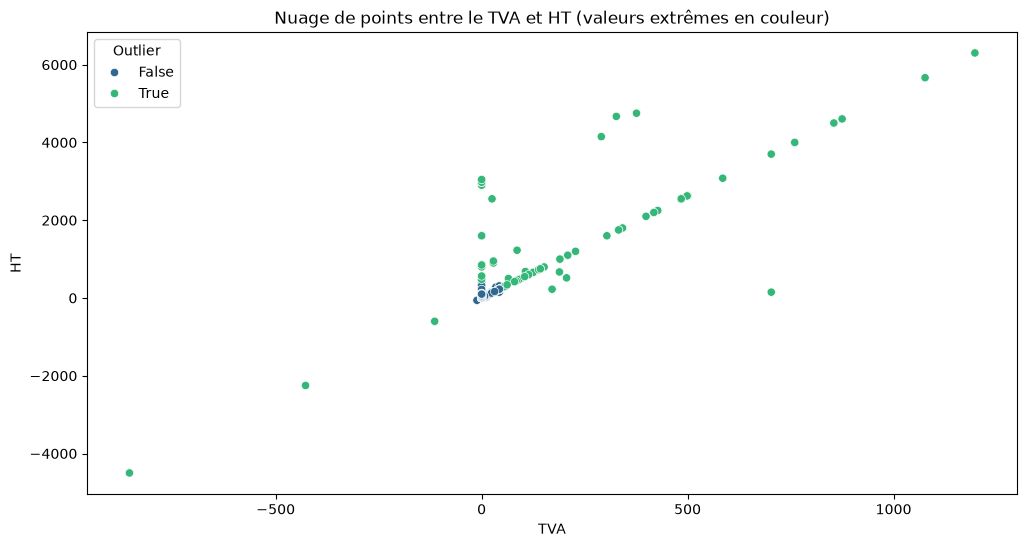

In [7]:

# Détecter les outliers pour les colonnes 'TVA' et 'TCL'
outliers_rm = detect_outliers_iqr(data, 'TVA')
outliers_price = detect_outliers_iqr(data, 'HT')

# Ajouter une colonne pour indiquer si la valeur est extrême
data['Outlier'] = False
data.loc[outliers_rm.index, 'Outlier'] = True
data.loc[outliers_price.index, 'Outlier'] = True

# Créer un nuage de points (scatter plot) avec Seaborn en mettant en évidence les valeurs extrêmes
plt.figure(figsize=(12, 6))
sns.scatterplot(data=data, x='TVA', y='HT', hue='Outlier', palette='viridis')
plt.xlabel('TVA')
plt.ylabel('HT')
plt.title("Nuage de points entre le TVA et HT (valeurs extrêmes en couleur)")
plt.show()

# Solutions pour traiter les valeurs extrêmes

| Type de valeur aberrante | Solutions pour les traiter                                                                                              |
|--------------------------|------------------------------------------------------------------------------------------------------------------------|
| Erreur                   | 1. Correction de l'erreur si possible (ex. erreurs de saisie)                                                           |
|                          | 2. Suppression de l'observation si la correction n'est pas possible et si l'erreur est clairement une anomalie 
|                          | 3. Remplacer par une valeur manquante et imputer avec les techniques d'imputation
|                          |      |
| Extrême                  | 1. Transformation des données (ex. logarithmique, racine carrée) pour réduire l'impact des valeurs extrêmes             |
|                          | 2. Winsorisation : remplacer les valeurs extrêmes par des percentiles spécifiques (ex. 1er et 99e percentiles)          |
|                         
|                          | 3. Utiliser des modèles d'apprentissage automatique robustes aux valeurs extrêmes (ex. modèles basés sur les rangs)     |
|                          | 4. Discrétiser la variable   |
|                          | 5. Faire le modèle avec et sans les valeurs extrêmes et analyser l'impact   |

# Transformation des données (ex. logarithmique) pour réduire l'impact des valeurs extrêmes

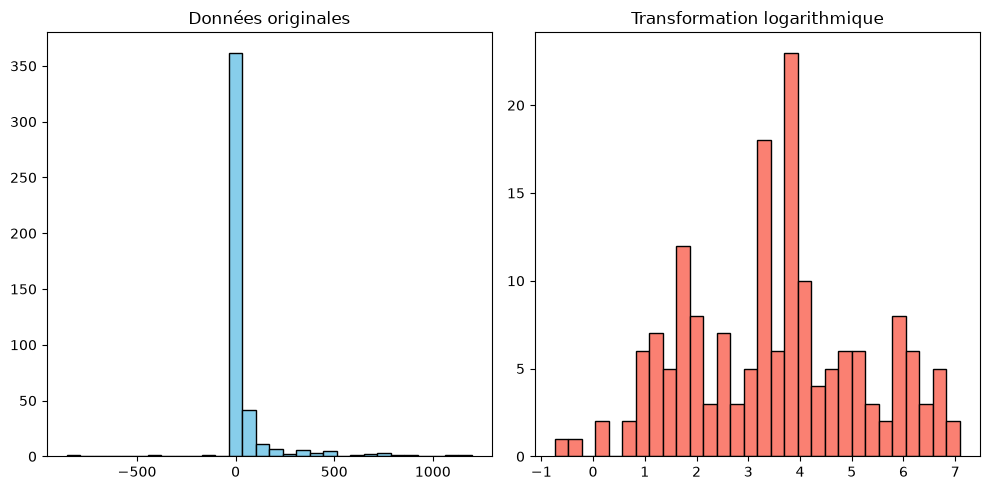

In [8]:
# Affichage de l'histogramme initial
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.hist(data['TVA'], bins=30, color='skyblue', edgecolor='black')
plt.title('Données originales')

# Transformation logarithmique des données (en excluant les valeurs négatives)
data_log = np.log(data['TVA'][data['TVA'] > 0])

# Affichage de l'histogramme après transformation logarithmique
plt.subplot(1, 2, 2)
plt.hist(data_log, bins=30, color='salmon', edgecolor='black')
plt.title('Transformation logarithmique')

plt.tight_layout()
plt.show()

# modèles d apprentissage automatique robustes aux valeurs extrêmes (ex. modèles basés sur les rangs)

In [9]:
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

# Générer des données avec des valeurs extrêmes
X, y = make_regression(n_samples=1000, n_features=10, noise=0.5, random_state=42)
outlier_indices = np.random.choice(len(y), size=100, replace=False)  # Sélection aléatoire d'indices pour les valeurs aberrantes
outlier_values = np.random.normal(loc=100, scale=10, size=len(outlier_indices))  # Exemple de valeurs aberrantes
y[outlier_indices] = outlier_values  # Remplacer les valeurs à ces indices par les valeurs aberrantes

# Diviser les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Utiliser un modèle de Régression Quantile (Gradient Boosting Quantile Regressor)
from sklearn.ensemble import GradientBoostingRegressor

quantile_alphas = [0.1, 0.5, 0.9]  # Choix des quantiles à prédire

for alpha in quantile_alphas:
    model = GradientBoostingRegressor(loss='quantile', alpha=alpha, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    print(f"Quantile {alpha}: MAE = {mae:.2f}")


Quantile 0.1: MAE = 88.04
Quantile 0.5: MAE = 42.29
Quantile 0.9: MAE = 103.06


# remplacer les valeurs aberrantes par des valeurs manquantes

In [11]:
# Remplacer les valeurs aberrantes par np.nan dans la colonne 'TVA'
#variable outliers declare fel cell 20
data.loc[outliers.index, 'TVA'] = np.nan

print(data)

# Afficher uniquement les valeurs aberrantes de la colonne 'TVA' après remplacement
print("Valeurs aberrantes remplacées par NaN :")
print(data.loc[outliers.index, 'TVA'])


      N°  Unnamed: 1       DATE  NCG             ICG     NCT   NCG.1  \
0      1           1 2023-01-12  401         FSR AUX  401S02  228300   
1      2           1 2023-01-05  401         FSR AUX  401S02  615002   
2      3           1 2023-01-16  401         FSR AUX  401D02  606200   
3      4           1 2023-01-26  401         FSR AUX  401D01  606100   
4      5           1 2023-01-04  402  SOUS TRAITANTS  402S01  611002   
..   ...         ...        ...  ...             ...     ...     ...   
583  585           1 2023-12-09  401         FSR AUX  401C01  606500   
584  586           1 2023-12-26  401         FSR AUX  401D01  606100   
585  587           1 2023-12-31  401         FSR AUX  401S03  606401   
586  588           1 2023-12-31  401         FSR AUX  401S03  606403   
587  589           1 2023-12-31  401         FSR AUX  401S03  606402   

            N° FCT                                        DESCRIPTION  SODEXO  \
0          23-0013                                    